# 03 · The Spam Filter

This is how spam was actually filtered for a decade: **Multinomial Naive Bayes on word
counts**, trained by literally counting how often each word appears in spam versus ham.
We rebuild it on a real SMS spam corpus, race it against logistic regression, and read the
words that most push a message toward spam — interpretability that comes for free from the
counts.

> Run `make data` first (it caches the dataset). The real UCI SMS Spam Collection is used
> when reachable, with a frozen synthetic corpus as fallback.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from src import artifacts
from src.config import SETTINGS
from src.datasets import text
from src.evaluation.comparison import run_arena
from src.models import MultinomialNB
from src.visualisation import plot_top_words

np.set_printoptions(precision=4, suppress=True)

In [2]:
frame = text.load_text_data()
X, vectorizer = text.vectorize(frame["text"].tolist(), max_features=SETTINGS.text.max_features)
y = frame["label"].to_numpy()
vocab = np.array(vectorizer.get_feature_names_out())

X_tr, X_te, y_tr, y_te, txt_tr, txt_te = train_test_split(
    X, y, frame["text"].tolist(), test_size=SETTINGS.test_size,
    stratify=y, random_state=SETTINGS.seed,
)
print(f"{len(y)} messages, {len(vocab)} vocabulary features "
      f"({int(y.sum())} spam / {int((y == 0).sum())} ham)")
print(f"train={len(y_tr)}  test={len(y_te)}")

5574 messages, 2000 vocabulary features (747 spam / 4827 ham)
train=4180  test=1394


## 1. Naive Bayes vs logistic regression

Same split, same features. We compare decision quality (accuracy, F1), training speed, and
— foreshadowing notebook 04 — probability quality (log loss).

In [3]:
table = run_arena(
    {
        "Multinomial NB": MultinomialNB(alpha=1.0),
        "Logistic Regression": LogisticRegression(max_iter=1000),
    },
    X_tr, y_tr, X_te, y_te,
)
print(table.to_string(float_format=lambda v: f"{v:.4f}"))

speedup = table.loc["Logistic Regression", "train_seconds"] / table.loc["Multinomial NB", "train_seconds"]
print(f"\nNaive Bayes trained ~{speedup:.0f}x faster than logistic regression.")

artifacts.save_json(
    {
        "results": table.reset_index().to_dict(orient="records"),
        "nb_train_speedup_vs_logreg": float(speedup),
    },
    "03_spam_arena",
)

                     accuracy     f1  train_seconds  mean_confidence  log_loss
model                                                                         
Multinomial NB         0.9857 0.9688         0.0703           0.9885    0.0794
Logistic Regression    0.9828 0.9610         0.3162           0.9805    0.0518

Naive Bayes trained ~4x faster than logistic regression.


PosixPath('/workspaces/naive_bayes_101/outputs/data/03_spam_arena.json')

## 2. Interpretable by construction: the top spam words

Because the model is just counts, we can read its mind. For each word, the difference in
log-probability between the spam and ham tables is exactly how hard that word pushes a
message toward spam.

  claim        +5.67
  prize        +5.43
  150p         +5.13
  18           +4.88
  tone         +4.88
  guaranteed   +4.85
  500          +4.82
  cs           +4.80
  awarded      +4.65
  1000         +4.55
  landline     +4.47
  uk           +4.47
  www          +4.46
  150ppm       +4.39
  ringtone     +4.35


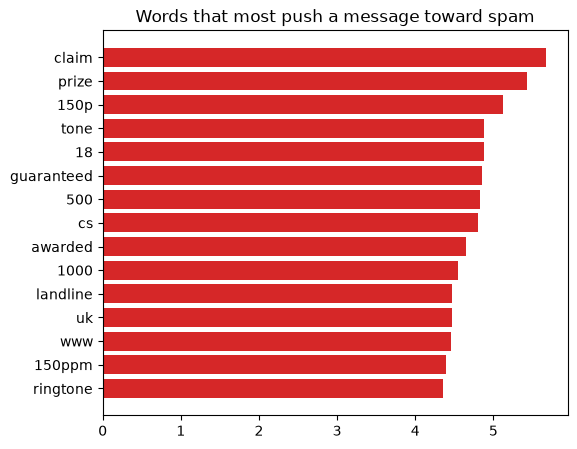

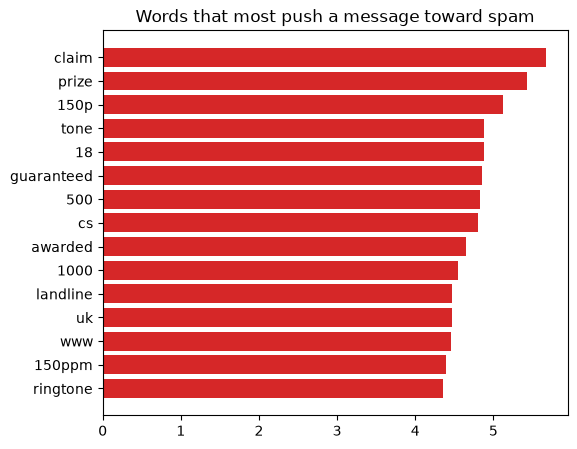

In [4]:
spam_model = MultinomialNB(alpha=1.0).fit(X_tr, y_tr)
spam_row = int(np.where(spam_model.classes_ == 1)[0][0])
ham_row = 1 - spam_row
spam_push = spam_model.feature_log_prob_[spam_row] - spam_model.feature_log_prob_[ham_row]

top_n = 15
top_idx = np.argsort(spam_push)[::-1][:top_n]
top_words = vocab[top_idx].tolist()
top_weights = spam_push[top_idx].tolist()
for w, s in zip(top_words, top_weights):
    print(f"  {w:<12} {s:+.2f}")

artifacts.save_json(
    {"top_spam_words": [{"word": w, "spam_push": s} for w, s in zip(top_words, top_weights)]},
    "03_top_spam_words",
)

fig = plot_top_words(top_words, top_weights, title="Words that most push a message toward spam")
artifacts.save_fig(fig, "03_top_spam_words")
fig

## 3. Scoring individual messages

In [5]:
examples = [
    "WINNER!! You have won a free prize, claim your cash now by calling this number",
    "Hey are we still on for lunch tomorrow?",
    "URGENT! Your account has been selected for a guaranteed loan, reply YES",
    "Can you send me the report before the meeting",
]
example_X = vectorizer.transform(examples).toarray().astype(float)
example_proba = spam_model.predict_proba(example_X)[:, spam_row]

scored = []
for msg, p in zip(examples, example_proba):
    verdict = "SPAM" if p >= 0.5 else "ham"
    print(f"[{verdict:>4}  P(spam)={p:.6f}]  {msg[:60]}")
    scored.append({"message": msg, "p_spam": float(p), "verdict": verdict})

artifacts.save_json({"examples": scored}, "03_example_messages")

[SPAM  P(spam)=1.000000]  WINNER!! You have won a free prize, claim your cash now by c
[ ham  P(spam)=0.000077]  Hey are we still on for lunch tomorrow?
[SPAM  P(spam)=1.000000]  URGENT! Your account has been selected for a guaranteed loan
[ ham  P(spam)=0.000043]  Can you send me the report before the meeting


PosixPath('/workspaces/naive_bayes_101/outputs/data/03_example_messages.json')

## Takeaway

Trained by counting, Naive Bayes matches logistic regression on this spam task and trains
far faster — and it tells you *why* it flagged a message. Keep an eye on that `log_loss`
column, though: the next notebook is about how badly the probabilities lie even when the
decisions are right.